# Лабораторная работа №1
## Анализ и прогнозирование временного ряда розничных продаж


In [1]:
# библиотеки
from pathlib import Path
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import detrend
from scipy.stats import jarque_bera
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")

## 1. Подготовка данных

Загружаю данные, перевожу дату в `datetime` и ставлю ее в индекс. Так как данные идут по месяцам, задаю месячную частоту.


In [4]:
# читаем данные
data_path = Path("retail_sales_mock_data.csv")
if not data_path.exists():
    data_path = Path("/mnt/data/retail_sales_mock_data.csv")

df = pd.read_csv(data_path)

# приводим дату к нормальному формату
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").set_index("Date").asfreq("MS")

print("Размер:", df.shape)
display(df.head())

Размер: (48, 3)


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


In [5]:
# базовая проверка данных
print("Типы данных:")
display(df.dtypes)

print("Пропуски:")
display(df.isna().sum())

print("Дубликаты:", df.reset_index().duplicated().sum())

display(df.describe().T)

Типы данных:


SalesAmount     int64
Promotion       int64
HolidayMonth    int64
dtype: object

Пропуски:


SalesAmount     0
Promotion       0
HolidayMonth    0
dtype: int64

Дубликаты: 0


,count,mean,std,min,25%,50%,75%,max
SalesAmount,48.0,11768.541667,2257.544863,7783.0,10219.75,11851.0,13014.0,17996.0
Promotion,48.0,0.125000,0.334219,0.0,0.00,0.0,0.0,1.0
HolidayMonth,48.0,0.083333,0.279310,0.0,0.00,0.0,0.0,1.0


### Короткий вывод

В датасете 48 наблюдений, то есть 4 года по месяцам. Основной ряд `SalesAmount`. Еще есть два бинарных признака: `Promotion` и `HolidayMonth`. Пропусков нет, поэтому дополнительно чистить данные не нужно.


## 2. EDA

Сначала посмотрю, как меняются продажи во времени, есть ли сезонность и связаны ли продажи с промо и праздничными месяцами.


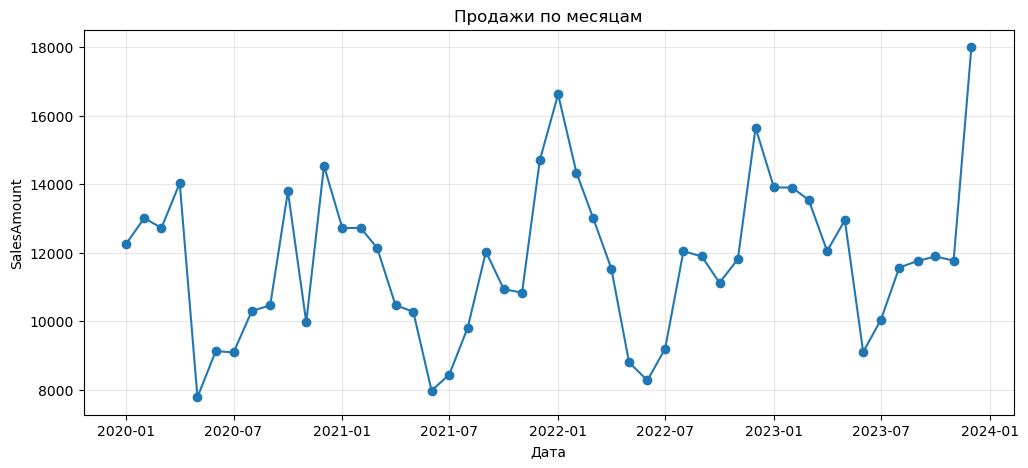

In [6]:
y = df["SalesAmount"].astype(float)

plt.figure(figsize=(12, 5))
plt.plot(y.index, y.values, marker="o")
plt.title("Продажи по месяцам")
plt.xlabel("Дата")
plt.ylabel("SalesAmount")
plt.grid(alpha=0.3)
plt.show()

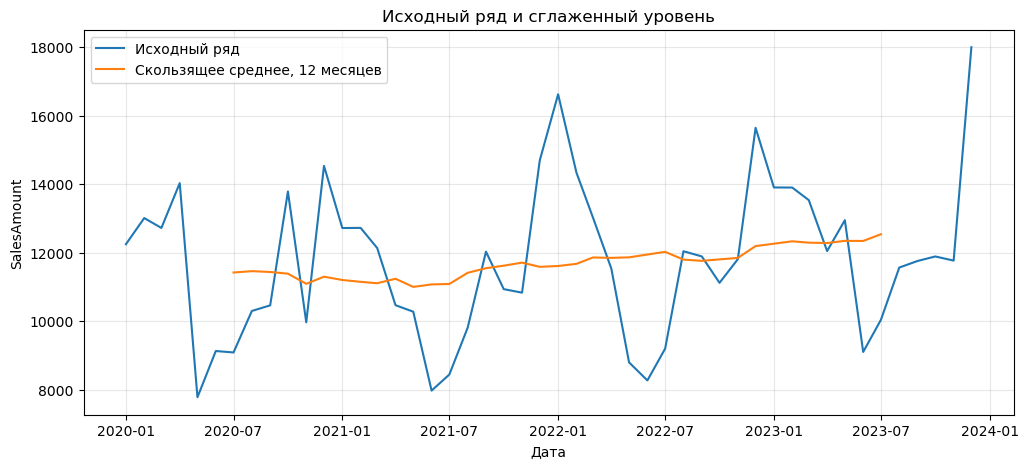

In [8]:
rolling_mean = y.rolling(12, center=True).mean()

plt.figure(figsize=(12, 5))
plt.plot(y.index, y.values, label="Исходный ряд")
plt.plot(rolling_mean.index, rolling_mean.values, label="Скользящее среднее, 12 месяцев")
plt.title("Исходный ряд и сглаженный уровень")
plt.xlabel("Дата")
plt.ylabel("SalesAmount")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

,mean,median,std
Month,,,
1,13873.75,13312.0,1960.74
2,13493.00,13456.0,752.95
3,12853.75,12872.5,584.21
4,12020.75,11792.5,1492.52
5,9952.75,9539.5,2245.04
6,8621.00,8688.5,586.09
7,9193.75,9144.0,656.04
8,10929.75,10933.0,1047.94
9,11536.50,11825.5,723.57


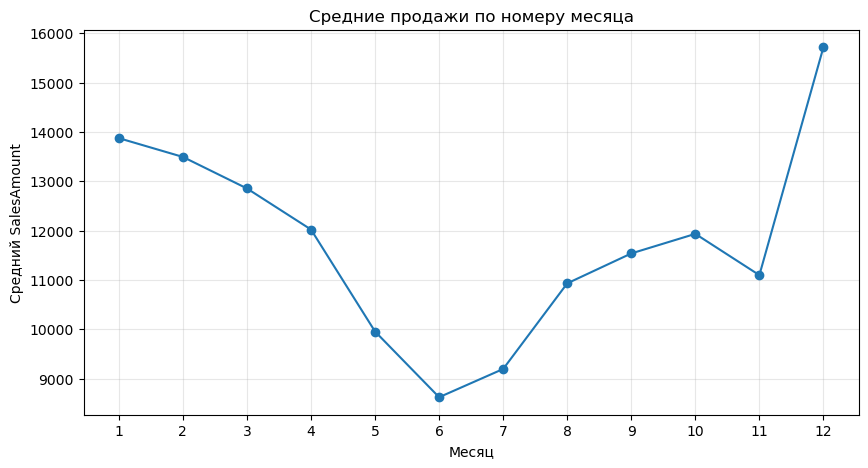

In [9]:
monthly_profile = (
    df.assign(Month=df.index.month)
      .groupby("Month")["SalesAmount"]
      .agg(["mean", "median", "std"])
)

display(monthly_profile.round(2))

plt.figure(figsize=(10, 5))
plt.plot(monthly_profile.index, monthly_profile["mean"], marker="o")
plt.xticks(range(1, 13))
plt.title("Средние продажи по номеру месяца")
plt.xlabel("Месяц")
plt.ylabel("Средний SalesAmount")
plt.grid(alpha=0.3)
plt.show()

In [11]:
promo_stats = df.groupby("Promotion")["SalesAmount"].agg(["count", "mean", "median"])
holiday_stats = df.groupby("HolidayMonth")["SalesAmount"].agg(["count", "mean", "median"])

print("Продажи в обычные месяцы и месяцы с промо:")
display(promo_stats.round(2))

print("Продажи в обычные и праздничные месяцы:")
display(holiday_stats.round(2))

Продажи в обычные месяцы и месяцы с промо:


,count,mean,median
Promotion,,,
0,42,11621.24,11791.0
1,6,12799.67,13367.5


Продажи в обычные и праздничные месяцы:


,count,mean,median
HolidayMonth,,,
0,44,11409.52,11764.5
1,4,15717.75,15170.5


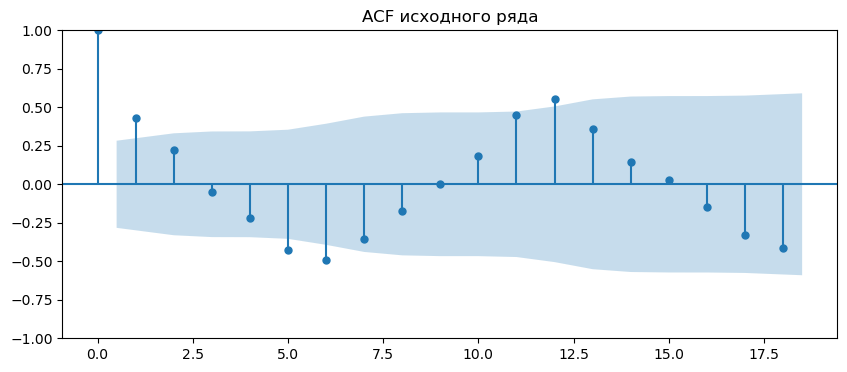

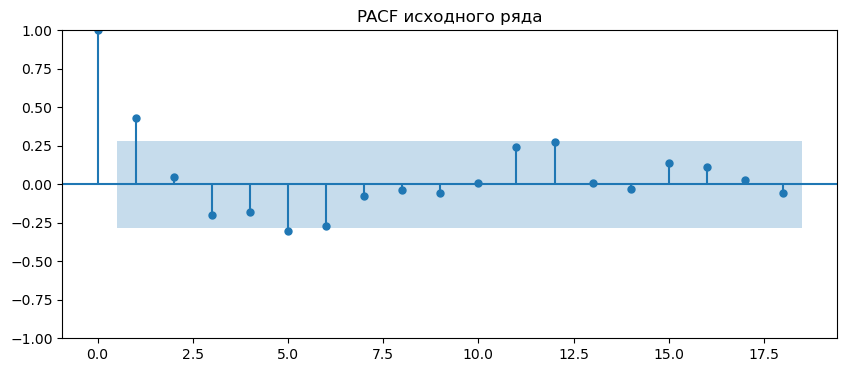

In [12]:
plt.figure(figsize=(10, 4))
plot_acf(y, lags=18, ax=plt.gca())
plt.title("ACF исходного ряда")
plt.show()

plt.figure(figsize=(10, 4))
plot_pacf(y, lags=18, method="ywm", ax=plt.gca())
plt.title("PACF исходного ряда")
plt.show()

In [13]:
# ADF-тест на стационарность
adf_stat, adf_pvalue, *_ = adfuller(y, autolag="AIC")

print(f"ADF statistic: {adf_stat:.4f}")
print(f"p-value: {adf_pvalue:.6f}")

if adf_pvalue < 0.05:
    print("Ряд можно считать стационарным на уровне значимости 5%")
else:
    print("Ряд нестационарный, возможно понадобится дифференцирование")

ADF statistic: -4.5142
p-value: 0.000185
Ряд можно считать стационарным на уровне значимости 5%


### Вывод по EDA

По графикам видно, что у ряда есть годовая сезонность. Продажи обычно выше в конце и начале года, а летом ниже. Сильного стабильного тренда нет, сезонность выражена заметнее.

`HolidayMonth` и `Promotion` тоже могут быть полезны: в некоторые праздничные и промо-месяцы продажи выше обычного. Поэтому эти признаки дальше добавлю в SARIMAX.


## 3. Декомпозиция ряда

Теперь посмотрю на структуру ряда тремя способами:

- классическая декомпозиция и STL;
- FFT;
- вейвлет-анализ.

Так можно сравнить, что каждый метод показывает на одном и том же ряду.


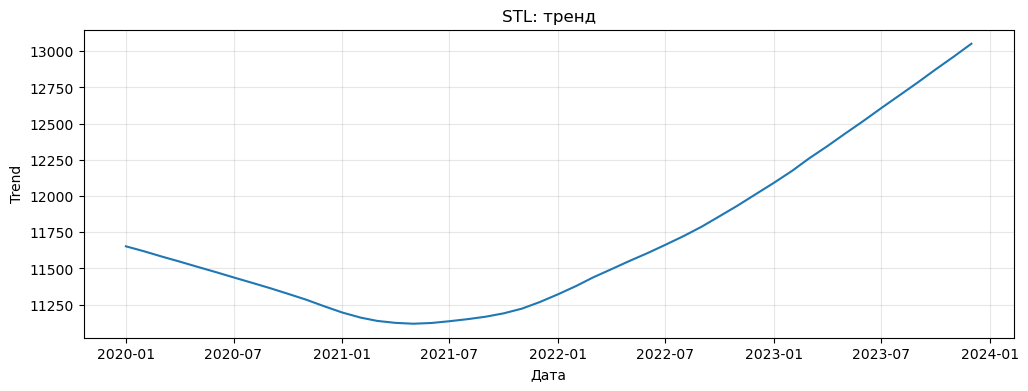

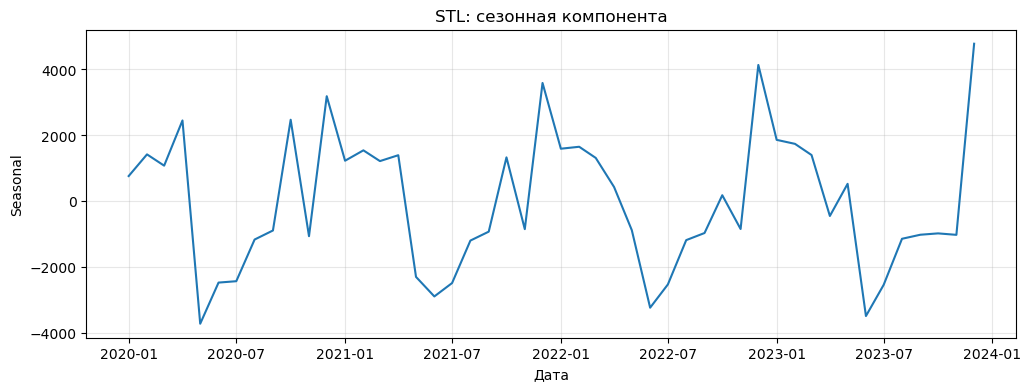

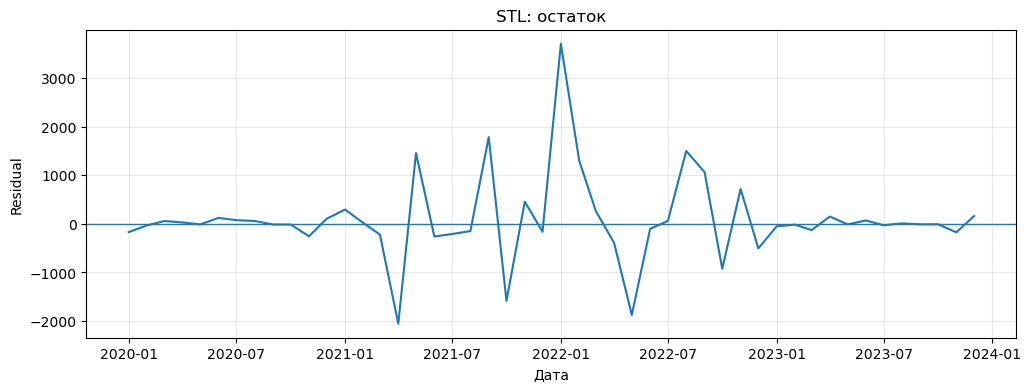

In [14]:
add_dec = seasonal_decompose(y, model="additive", period=12, extrapolate_trend="freq")
mul_dec = seasonal_decompose(y, model="multiplicative", period=12, extrapolate_trend="freq")
stl = STL(y, period=12, robust=True).fit()

plt.figure(figsize=(12, 4))
plt.plot(stl.trend)
plt.title("STL: тренд")
plt.xlabel("Дата")
plt.ylabel("Trend")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(stl.seasonal)
plt.title("STL: сезонная компонента")
plt.xlabel("Дата")
plt.ylabel("Seasonal")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(stl.resid)
plt.axhline(0, linewidth=1)
plt.title("STL: остаток")
plt.xlabel("Дата")
plt.ylabel("Residual")
plt.grid(alpha=0.3)
plt.show()

In [15]:
comparison_decomp = pd.DataFrame({
    "additive_seasonal": add_dec.seasonal,
    "multiplicative_seasonal": mul_dec.seasonal,
    "stl_seasonal": stl.seasonal
})

display(comparison_decomp.head(12).round(3))

,additive_seasonal,multiplicative_seasonal,stl_seasonal
Date,,,
2020-01-01,2198.486,1.189,766.188
2020-02-01,1803.639,1.155,1423.804
2020-03-01,1146.729,1.098,1081.564
2020-04-01,329.007,1.029,2453.560
2020-05-01,-1728.986,0.850,-3715.122
2020-06-01,-3106.541,0.736,-2466.782
2020-07-01,-2566.474,0.781,-2424.939
2020-08-01,-870.439,0.926,-1160.367
2020-09-01,-294.863,0.976,-885.749


### 3.1. FFT

FFT показывает, какие периодичности сильнее всего представлены в ряду. Перед расчетом убираю линейный тренд, чтобы низкие частоты не забивали спектр.


Наиболее сильные периодичности:


,frequency,period_months,power
3,0.083,12.000,3.376921e+09
11,0.250,4.000,4.068245e+08
23,0.500,2.000,2.581354e+08
7,0.167,6.000,1.891419e+08
19,0.417,2.400,1.650044e+08
22,0.479,2.087,1.541550e+08
21,0.458,2.182,1.520215e+08
12,0.271,3.692,1.270382e+08


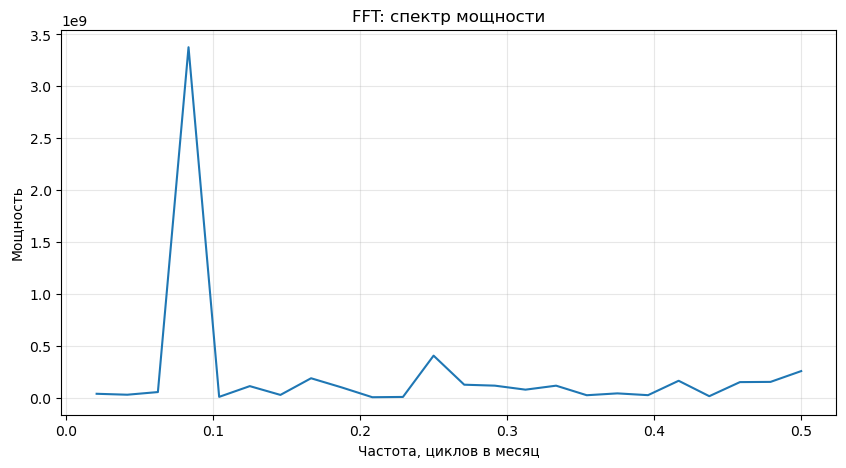

In [16]:
y_detrended = detrend(y.values)
n = len(y_detrended)

fft_values = np.fft.rfft(y_detrended)
frequencies = np.fft.rfftfreq(n, d=1)
power = np.abs(fft_values) ** 2

fft_table = pd.DataFrame({
    "frequency": frequencies[1:],
    "period_months": 1 / frequencies[1:],
    "power": power[1:]
}).sort_values("power", ascending=False)

print("Наиболее сильные периодичности:")
display(fft_table.head(8).round(3))

plt.figure(figsize=(10, 5))
fft_sorted = fft_table.sort_values("frequency")
plt.plot(fft_sorted["frequency"], fft_sorted["power"])
plt.title("FFT: спектр мощности")
plt.xlabel("Частота, циклов в месяц")
plt.ylabel("Мощность")
plt.grid(alpha=0.3)
plt.show()

### 3.2. Вейвлет-анализ

FFT показывает частоты сразу по всему ряду. Вейвлет-анализ дополнительно показывает, как сила этих периодичностей меняется со временем. Здесь использую вейвлет Морле.


,scale,mean_power
11,12,37917077.33
10,11,37349878.95
12,13,28873453.42
9,10,25060601.13
13,14,17639620.10
8,9,10443952.76
14,15,9017889.24
0,1,8485338.20


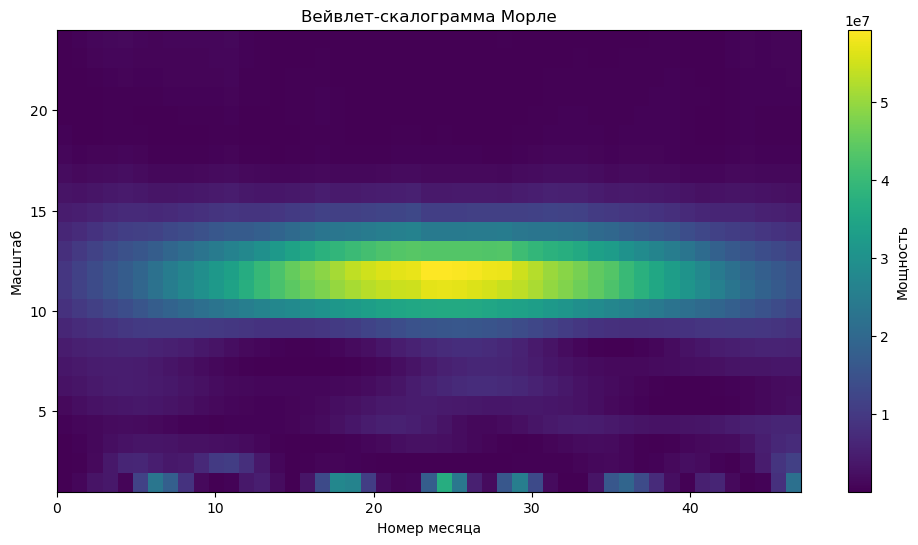

In [20]:
def morlet_wavelet(length, scale, w=6.0):
    # вейвлет Морле
    half = length // 2
    t = np.arange(-half, half + 1, dtype=float)
    x = t / scale
    wavelet = (np.pi ** -0.25) * np.exp(1j * w * x) * np.exp(-(x ** 2) / 2)
    return wavelet / np.sqrt(scale)

series_centered = y.values - y.mean()
scales = np.arange(1, 25)

coef_list = []
for scale in scales:
    wavelet = morlet_wavelet(len(series_centered), scale)
    coef = np.convolve(series_centered, np.conj(wavelet[::-1]), mode="same")
    coef_list.append(coef)

wavelet_coef = np.array(coef_list)
wavelet_power = np.abs(wavelet_coef) ** 2

wavelet_table = pd.DataFrame({
    "scale": scales,
    "mean_power": wavelet_power.mean(axis=1)
}).sort_values("mean_power", ascending=False)

display(wavelet_table.head(8).round(2))

plt.figure(figsize=(12, 6))
plt.imshow(
    wavelet_power,
    aspect="auto",
    origin="lower",
    extent=[0, len(y) - 1, scales.min(), scales.max()]
)
plt.title("Вейвлет-скалограмма Морле")
plt.xlabel("Номер месяца")
plt.ylabel("Масштаб")
plt.colorbar(label="Мощность")
plt.show()

### Вывод по декомпозиции

Все три метода показывают сезонную структуру, но по-разному.

- STL удобно использовать, когда нужно отдельно посмотреть тренд, сезонность и остаток.
- FFT хорошо показывает основные периоды. Здесь сильнее всего выделяется период около 12 месяцев.
- Вейвлет-анализ показывает не только периодичность, но и то, как она меняется по времени.

Для SARIMAX дальше беру сезонный период 12 месяцев. Для этого ряда STL проще всего интерпретировать, FFT хорошо подтверждает годовой цикл, а вейвлет нужен скорее как дополнительная проверка.


## 4. ARIMA и SARIMAX

Последние 12 месяцев оставляю на тест. Это полный год, поэтому можно нормально проверить сезонный прогноз. Остальные 36 месяцев идут в train.

Параметры моделей подбираю по AIC только на обучающей выборке. В SARIMAX дополнительно использую признаки `Promotion` и `HolidayMonth`.


In [21]:
test_size = 12

train = df.iloc[:-test_size].copy()
test = df.iloc[-test_size:].copy()

y_train = train["SalesAmount"].astype(float)
y_test = test["SalesAmount"].astype(float)

exog_cols = ["Promotion", "HolidayMonth"]
X_train = train[exog_cols].astype(float)
X_test = test[exog_cols].astype(float)

print("Train:", train.index.min().date(), "-", train.index.max().date(), "|", len(train), "месяцев")
print("Test: ", test.index.min().date(), "-", test.index.max().date(), "|", len(test), "месяцев")

Train: 2020-01-01 - 2022-12-01 | 36 месяцев
Test:  2023-01-01 - 2023-12-01 | 12 месяцев


### 4.1. Подбор ARIMA

Переберу несколько небольших значений `p`, `d`, `q` и выберу вариант с минимальным AIC. Сетка специально небольшая, потому что данных всего 36 точек в train.


In [23]:
# небольшой перебор параметров ARIMA
arima_results = []

for p, d, q in itertools.product(range(4), range(2), range(4)):
    if (p, d, q) == (0, 0, 0):
        continue

    try:
        trend = "t" if d == 1 else "c"
        model = ARIMA(y_train, order=(p, d, q), trend=trend).fit()

        arima_results.append({
            "order": (p, d, q),
            "AIC": model.aic,
            "BIC": model.bic
        })
    except Exception:
        pass

arima_results = pd.DataFrame(arima_results).sort_values("AIC").reset_index(drop=True)
display(arima_results.head(10).round(2))

best_arima_order = tuple(arima_results.iloc[0]["order"])
print("Лучший order:", best_arima_order)

,order,AIC,BIC
0,"(2, 1, 3)",640.74,651.63
1,"(0, 1, 0)",642.42,645.53
2,"(3, 1, 1)",642.50,651.84
3,"(3, 1, 2)",642.63,653.52
4,"(0, 1, 3)",643.19,650.96
5,"(1, 1, 3)",643.45,652.78
6,"(1, 1, 0)",643.74,648.40
7,"(3, 1, 3)",643.76,656.20
8,"(2, 0, 3)",644.06,655.14
9,"(0, 1, 1)",644.28,648.95


Лучший order: (2, 1, 3)


### 4.2. Подбор SARIMAX

Для SARIMAX тоже делаю небольшой перебор параметров. Сезонный период беру равным 12, потому что это видно и по графикам, и по FFT.


In [24]:
# параметры для перебора SARIMAX
sarimax_results = []

orders = [
    order for order in itertools.product(range(2), range(2), range(2))
    if order != (0, 0, 0)
]

seasonal_orders = [
    (0, 1, 1, 12),
    (1, 1, 0, 12),
    (1, 1, 1, 12)
]

for order in orders:
    for seasonal_order in seasonal_orders:
        try:
            trend = "t" if order[1] == 1 else "c"

            model = SARIMAX(
                y_train,
                exog=X_train,
                order=order,
                seasonal_order=seasonal_order,
                trend=trend,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False, maxiter=200)

            if model.mle_retvals.get("converged", True):
                sarimax_results.append({
                    "order": order,
                    "seasonal_order": seasonal_order,
                    "AIC": model.aic,
                    "BIC": model.bic
                })
        except Exception:
            pass

sarimax_results = pd.DataFrame(sarimax_results).sort_values("AIC").reset_index(drop=True)
display(sarimax_results.head(10).round(2))

best_sarimax_order = tuple(sarimax_results.iloc[0]["order"])
best_sarimax_seasonal = tuple(sarimax_results.iloc[0]["seasonal_order"])

print("Лучший order:", best_sarimax_order)
print("Лучший seasonal_order:", best_sarimax_seasonal)

,order,seasonal_order,AIC,BIC
0,"(0, 1, 1)","(0, 1, 1, 12)",151.48,152.67
1,"(1, 1, 1)","(0, 1, 1, 12)",151.89,153.27
2,"(0, 1, 1)","(1, 1, 1, 12)",153.35,154.73
3,"(1, 1, 1)","(1, 1, 1, 12)",154.54,156.12
4,"(0, 0, 1)","(0, 1, 1, 12)",158.38,160.20
5,"(1, 0, 1)","(0, 1, 1, 12)",162.53,164.65
6,"(0, 0, 1)","(1, 1, 1, 12)",163.31,165.43
7,"(1, 1, 1)","(1, 1, 0, 12)",168.62,170.74
8,"(1, 1, 0)","(0, 1, 1, 12)",168.92,170.73
9,"(1, 1, 0)","(1, 1, 0, 12)",169.50,171.32


Лучший order: (0, 1, 1)
Лучший seasonal_order: (0, 1, 1, 12)


### Вывод по подбору моделей

По AIC на тренировочной выборке были выбраны параметры для обеих моделей.

Для ARIMA и SARIMAX AIC и BIC я использую в первую очередь для выбора параметров внутри каждого типа модели. Напрямую сравнивать значения критериев между ARIMA и SARIMAX не совсем корректно, потому что модели устроены по-разному и после сезонного дифференцирования используется другое эффективное число наблюдений.

ARIMA учитывает только прошлые значения ряда, а SARIMAX дополнительно использует сезонность и внешние признаки. Сетка параметров специально небольшая, потому что в train всего 36 наблюдений.

## 5. Прогноз и метрики

Обучаю лучшие модели на train и строю прогноз на последние 12 месяцев. После этого считаю MSE, R², AIC и BIC.


In [25]:
best_arima = ARIMA(
    y_train,
    order=best_arima_order,
    trend="t" if best_arima_order[1] == 1 else "c"
).fit()

best_sarimax = SARIMAX(
    y_train,
    exog=X_train,
    order=best_sarimax_order,
    seasonal_order=best_sarimax_seasonal,
    trend="t" if best_sarimax_order[1] == 1 else "c",
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=200)

arima_forecast = best_arima.get_forecast(steps=test_size)
sarimax_forecast = best_sarimax.get_forecast(steps=test_size, exog=X_test)

pred_arima = pd.Series(arima_forecast.predicted_mean, index=y_test.index, name="ARIMA")
pred_sarimax = pd.Series(sarimax_forecast.predicted_mean, index=y_test.index, name="SARIMAX")

forecast_table = pd.DataFrame({
    "fact": y_test,
    "ARIMA": pred_arima,
    "SARIMAX": pred_sarimax
})

display(forecast_table.round(1))

,fact,ARIMA,SARIMAX
Date,,,
2023-01-01,13904.0,14631.4,14862.9
2023-02-01,13901.0,13928.4,14880.2
2023-03-01,13534.0,13005.1,14092.9
2023-04-01,12048.0,12169.8,12659.4
2023-05-01,12949.0,11635.7,12432.7
2023-06-01,9104.0,11487.0,9460.7
2023-07-01,10042.0,11687.2,10666.7
2023-08-01,11566.0,12116.9,12755.7
2023-09-01,11759.0,12624.1,13472.9


In [26]:
def model_metrics(y_true, y_pred, fitted_model):
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic
    }

metrics = pd.DataFrame({
    "ARIMA": model_metrics(y_test, pred_arima, best_arima),
    "SARIMAX": model_metrics(y_test, pred_sarimax, best_sarimax)
}).T

display(metrics.round(3))

,MSE,R2,AIC,BIC
ARIMA,3018146.303,0.347,640.744,651.631
SARIMAX,998394.639,0.784,151.482,152.665


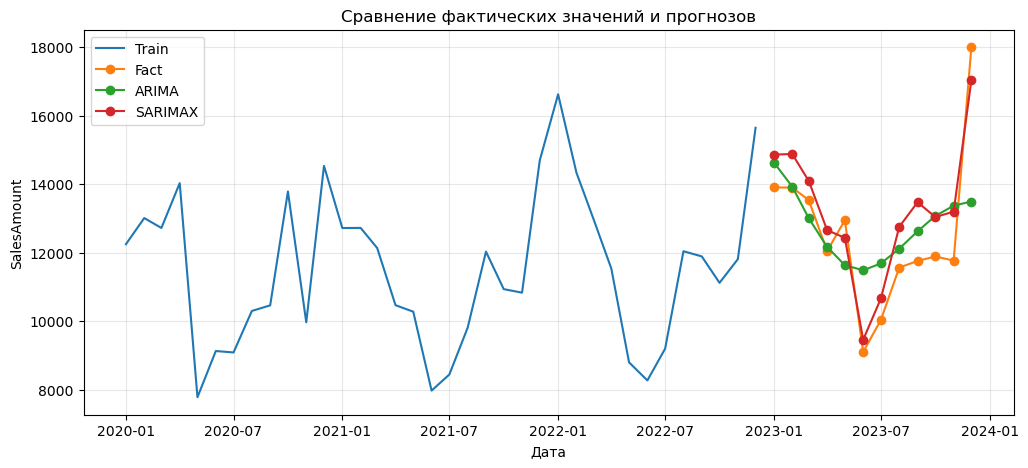

In [27]:

plt.figure(figsize=(12, 5))
plt.plot(y_train.index, y_train, label="Train")
plt.plot(y_test.index, y_test, marker="o", label="Fact")
plt.plot(pred_arima.index, pred_arima, marker="o", label="ARIMA")
plt.plot(pred_sarimax.index, pred_sarimax, marker="o", label="SARIMAX")
plt.title("Сравнение фактических значений и прогнозов")
plt.xlabel("Дата")
plt.ylabel("SalesAmount")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Вывод по качеству

На тестовом году получилось:

- ARIMA: MSE ≈ 3 018 677, R² ≈ 0.347;
- SARIMAX: MSE ≈ 998 395, R² ≈ 0.784.

SARIMAX дает заметно меньшую ошибку и лучше объясняет изменение продаж на тесте. То есть сезонность и дополнительные признаки здесь реально помогают.

12 месяцев является нормальным горизонтом для этой выборки: это целый сезонный цикл, а train при этом остается достаточно большим.


## 6. Остатки моделей

В конце проверю, похожи ли остатки на случайный шум. Для этого использую:

- Jarque–Bera — нормальность;
- Ljung–Box — автокорреляция;
- ARCH test — изменение дисперсии.

Если `p-value > 0.05`, то явных проблем по соответствующему тесту нет.


In [29]:
def clean_residuals(model):
    resid = pd.Series(model.resid).replace([np.inf, -np.inf], np.nan).dropna()
    burn = int(getattr(model, "loglikelihood_burn", 0))
    if burn > 0 and burn < len(resid):
        resid = resid.iloc[burn:]
    return resid

def residual_tests(model, model_name):
    resid = clean_residuals(model)

    jb = jarque_bera(resid)

    lb_lag = min(8, max(1, len(resid) // 4))
    lb = acorr_ljungbox(resid, lags=[lb_lag], return_df=True)

    arch_lags = min(5, max(1, len(resid) // 5))
    arch = het_arch(resid, nlags=arch_lags)

    return {
        "Model": model_name,
        "N_resid": len(resid),
        "JB_pvalue": jb.pvalue,
        "LjungBox_pvalue": lb["lb_pvalue"].iloc[0],
        "ARCH_pvalue": arch[1]
    }

residual_results = pd.DataFrame([
    residual_tests(best_arima, "ARIMA"),
    residual_tests(best_sarimax, "SARIMAX")
]).set_index("Model")

display(residual_results.round(4))

,N_resid,JB_pvalue,LjungBox_pvalue,ARCH_pvalue
Model,,,,
ARIMA,35,0.9170,0.7096,0.3679
SARIMAX,9,0.9502,0.1310,0.7319


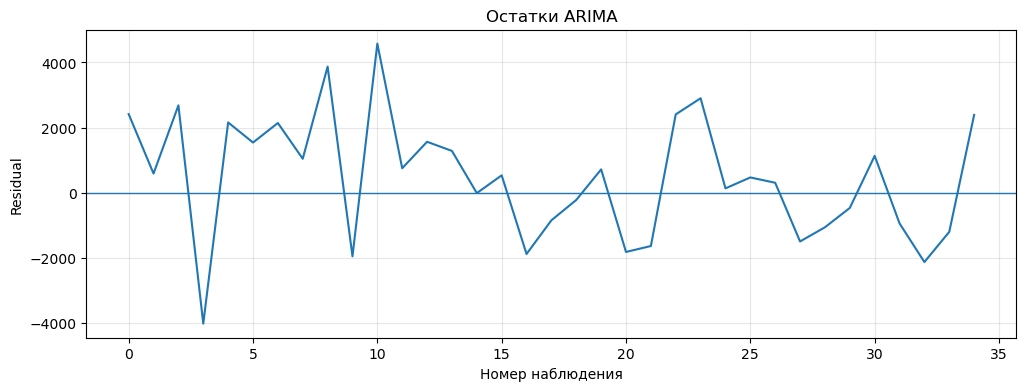

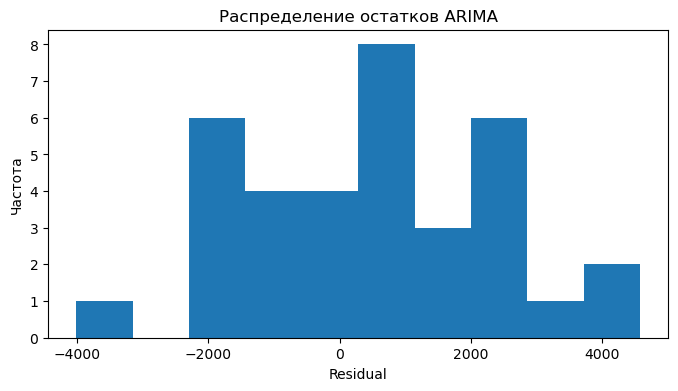

In [31]:
arima_resid = clean_residuals(best_arima)

plt.figure(figsize=(12, 4))
plt.plot(arima_resid.values)
plt.axhline(0, linewidth=1)
plt.title("Остатки ARIMA")
plt.xlabel("Номер наблюдения")
plt.ylabel("Residual")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(arima_resid, bins=10)
plt.title("Распределение остатков ARIMA")
plt.xlabel("Residual")
plt.ylabel("Частота")
plt.show()

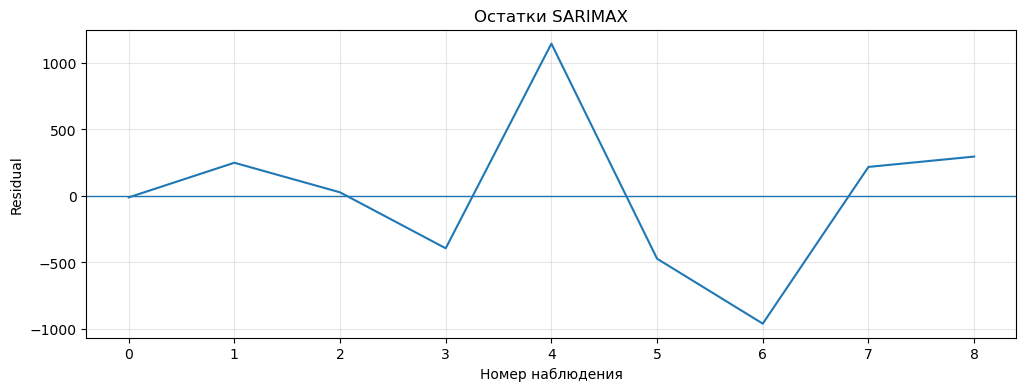

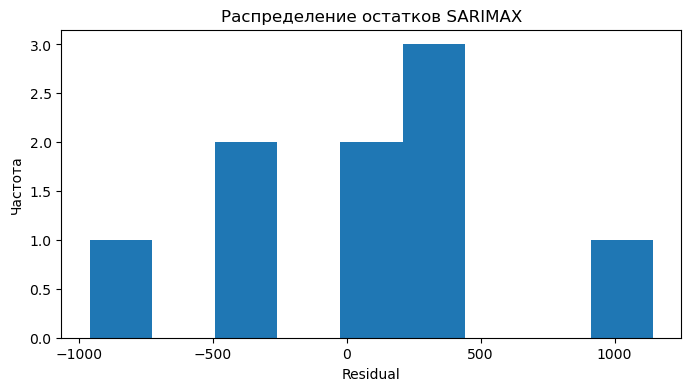

In [32]:
sarimax_resid = clean_residuals(best_sarimax)

plt.figure(figsize=(12, 4))
plt.plot(sarimax_resid.values)
plt.axhline(0, linewidth=1)
plt.title("Остатки SARIMAX")
plt.xlabel("Номер наблюдения")
plt.ylabel("Residual")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(sarimax_resid, bins=max(5, min(10, len(sarimax_resid))))
plt.title("Распределение остатков SARIMAX")
plt.xlabel("Residual")
plt.ylabel("Частота")
plt.show()

### Вывод по остаткам

У ARIMA по тестам остатков явных проблем не видно: p-value для проверок нормальности, автокорреляции и гетероскедастичности выше 0.05.

Для SARIMAX результаты тестов тоже выглядят нормально, но после учета сезонной части остается мало эффективных остатков. Поэтому здесь эти проверки лучше воспринимать как дополнительный ориентир, а не как сильное доказательство того, что остатки полностью соответствуют всем предположениям модели.

В целом по диагностике обе модели выглядят приемлемо, но по качеству прогноза на тесте SARIMAX лучше.

# Итог

В работе я посмотрел временной ряд продаж и сравнил две модели прогнозирования.

Основные результаты:

1. В ряду есть выраженная сезонность примерно 12 месяцев.
2. Это подтверждается STL, FFT и вейвлет-анализом.
3. По AIC были выбраны ARIMA(2, 1, 3) и SARIMAX(0, 1, 1) × (0, 1, 1, 12).
4. На тестовых 12 месяцах SARIMAX показала результат лучше: R² = 0.784 против 0.347 у ARIMA, MSE тоже заметно ниже.
5. По тестам остатков критичных проблем у моделей не видно.

Итогово для этого ряда я бы выбрал SARIMAX, потому что она лучше учитывает годовую сезонность и дополнительные признаки.
